# 01 — EDA: is the survival target feasible for class 7 (Scaling in PCK)?

**Question this notebook answers (CLAUDE.md "Known risk"):** PI-PatchSurv needs windows that end
*before* scaling onset t0, so each class-7 instance must contain enough labelled-normal data before
its first class-7 sample. If most instances start already scaled, there is nothing to forecast
and we must fall back to forecasting the restriction index (RI) crossing a threshold.

Steps: (1) index every 3W file, (2) per class-7 instance: well, duration, onset, pre-onset normal
duration, (3) other instances of the same wells (extra normal history), (4) plots, (5) verdict.

Data: `python src/data/download_3w.py` first (3W v2.0.0, pinned commit).

In [1]:
# WHY these imports only: EDA must run on the light env (no torch) so anyone can reproduce it fast.
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DS = ROOT / "data" / "3w" / "dataset"
TABLES, FIGS = ROOT / "results" / "tables", ROOT / "results" / "figures"
assert DS.exists(), "run: python src/data/download_3w.py"
pd.set_option("display.width", 200, "display.max_rows", 100)

## 1. Index all instances
Folder name = label; filename = source. Real files are `WELL-<id>_<YYYYMMDDHHMMSS>.parquet`
so the **well ID and start time come free from the name** — no need to open 1.7 GB to build the index.
Well ID is what every split groups on (CLAUDE.md rule: never split windows randomly).

In [2]:
rows = []
for f in sorted(DS.glob("*/*.parquet")):
    m = re.match(r"(WELL-\d+)_(\d{14})", f.stem)
    rows.append(dict(label=int(f.parent.name),
                     source="real" if m else f.stem.split("_")[0].lower(),  # simulated / drawn
                     well=m.group(1) if m else None,
                     start=pd.to_datetime(m.group(2), format="%Y%m%d%H%M%S") if m else pd.NaT,
                     path=f))
idx = pd.DataFrame(rows)
# Sanity check against the Sci. Data paper: 1,119 real / 1,089 simulated / 20 drawn.
print(idx.source.value_counts().to_dict())
idx.pivot_table(index="label", columns="source", values="path", aggfunc="count", fill_value=0)

{'real': 1119, 'simulated': 1089, 'drawn': 20}


source,drawn,real,simulated
label,,,
0,0,594,0
1,10,4,114
2,0,22,16
3,0,32,74
4,0,343,0
5,0,11,439
6,0,6,215
7,10,36,0
8,0,14,81


## 2. Class-7 instances: duration, onset t0, pre-onset normal
Only the `class` column is read (Parquet is columnar → fast). Definitions, matching CLAUDE.md §Labels:
* **t0** = first timestamp with class ∈ {107, 7}. EDA finding: v2 *does* label the class-7 transient
  as 107 (TRANSIENT_OFFSET = 100 in dataset.ini), and most real instances never reach steady 7 —
  so onset = start of the transient. CLAUDE.md's "no transient label" is outdated.
* **t_steady** = first class == 7 (often absent).
* **pre-onset normal** = time with class == 0 before t0 (rows × 1 s; data is 1 Hz).
* **pre-onset span** = t0 − first timestamp (includes unlabelled/NaN rows; upper bound).

In [3]:
def describe_instance(path):
    s = pd.read_parquet(path, columns=["class"])["class"]
    t = s.index
    is7 = s.isin([7, 107]).to_numpy(dtype=bool, na_value=False)  # WHY 107 too: transient = onset
    steady = (s == 7).to_numpy(dtype=bool, na_value=False)
    t0 = t[is7.argmax()] if is7.any() else pd.NaT
    pre = (t < t0) if is7.any() else np.ones(len(t), bool)
    return dict(n_rows=len(s), t_start=t[0], t_end=t[-1],
                duration_h=(t[-1] - t[0]).total_seconds() / 3600,
                t0=t0, has_steady7=steady.any(),
                pre_span_h=((t0 - t[0]).total_seconds() / 3600) if is7.any() else np.nan,
                pre_normal_h=((s[pre] == 0).sum()) / 3600,
                post_h=is7.sum() / 3600,  # hours labelled 107/7
                nan_label_frac=s.isna().mean(),
                labels=sorted(int(v) for v in s.dropna().unique()))

c7 = idx[idx.label == 7].copy()
c7 = pd.concat([c7.reset_index(drop=True), pd.DataFrame([describe_instance(p) for p in c7.path])], axis=1)
# Any 107 (transient) labels? CLAUDE.md says none — verify instead of assuming (answer: yes, see below).
print("labels seen in class-7 files:", sorted({l for ls in c7.labels for l in ls}))
cols = ["source","well","t_start","duration_h","t0","has_steady7","pre_span_h","pre_normal_h","post_h","nan_label_frac","labels"]
c7_real = c7[c7.source == "real"].sort_values(["well","t_start"])
c7_real[cols].round({c: 2 for c in ["duration_h","pre_span_h","pre_normal_h","post_h","nan_label_frac"]})

labels seen in class-7 files: [0, 7, 107]


,source,well,t_start,duration_h,t0,has_steady7,pre_span_h,pre_normal_h,post_h,nan_label_frac,labels
10,real,WELL-00001,2017-02-26 13:01:46,21.29,2017-02-26 23:24:16,True,10.38,9.38,10.91,0.05,"[0, 7, 107]"
11,real,WELL-00006,2018-06-18 10:30:00,36.60,2018-06-18 13:00:01,True,2.50,1.50,34.10,0.03,"[0, 7, 107]"
12,real,WELL-00006,2018-06-20 15:29:03,32.46,2018-06-20 19:57:28,True,4.47,3.47,27.98,0.03,"[0, 7, 107]"
13,real,WELL-00021,2018-06-11 01:12:18,12.94,2018-06-11 07:04:06,True,5.86,4.86,7.07,0.08,"[0, 7, 107]"
14,real,WELL-00021,2019-04-03 01:33:07,13.45,2019-04-03 09:59:05,False,8.43,7.43,5.02,0.07,"[0, 107]"
15,real,WELL-00022,2018-08-02 23:38:38,84.36,2018-08-03 23:35:24,False,23.95,22.95,60.41,0.01,"[0, 107]"
16,real,WELL-00022,2018-09-12 02:58:00,156.03,2018-09-12 11:03:28,False,8.09,7.09,147.94,0.01,"[0, 107]"
17,real,WELL-00022,2018-09-19 00:32:40,80.46,2018-09-19 11:30:37,False,10.97,9.97,69.49,0.01,"[0, 107]"
18,real,WELL-00022,2018-09-25 00:34:47,213.42,2018-09-25 15:12:34,False,14.63,13.63,198.79,0.00,"[0, 107]"
19,real,WELL-00022,2018-10-07 08:07:00,109.88,2018-10-08 06:39:01,False,22.53,21.53,87.35,0.01,"[0, 107]"


In [4]:
# Hand-drawn instances: training-only augmentation, but we still want to know if they have a pre-onset part.
c7[c7.source != "real"][["path","duration_h","pre_span_h","pre_normal_h","post_h","labels"]].assign(path=lambda d: d.path.map(lambda p: p.name)).round(2)

,path,duration_h,pre_span_h,pre_normal_h,post_h,labels
0,DRAWN_00001.parquet,96.0,11.48,11.48,84.52,"[0, 107]"
1,DRAWN_00002.parquet,96.0,9.61,9.61,86.39,"[0, 107]"
2,DRAWN_00003.parquet,96.0,7.66,7.66,88.34,"[0, 107]"
3,DRAWN_00004.parquet,12.0,1.91,1.91,10.09,"[0, 7, 107]"
4,DRAWN_00005.parquet,96.0,9.61,9.61,86.39,"[0, 107]"
5,DRAWN_00006.parquet,96.0,17.26,17.26,78.74,"[0, 7, 107]"
6,DRAWN_00007.parquet,96.0,9.61,9.61,86.39,"[0, 7, 107]"
7,DRAWN_00008.parquet,48.0,2.85,2.85,45.15,"[0, 107]"
8,DRAWN_00009.parquet,12.0,1.91,1.91,10.09,"[0, 107]"
9,DRAWN_00010.parquet,24.0,2.40,2.40,21.60,"[0, 7, 107]"


In [5]:
# Persist the table: the Phase 3 report (deliverable 2) cites these numbers directly.
TABLES.mkdir(parents=True, exist_ok=True)
c7.drop(columns="path").assign(file=c7.path.map(lambda p: p.name)).to_csv(TABLES / "class7_instances.csv", index=False)
print(c7_real[["duration_h","pre_span_h","pre_normal_h","post_h"]].describe(percentiles=[.1,.25,.5,.75,.9]).round(2))

       duration_h  pre_span_h  pre_normal_h  post_h
count       36.00       36.00         36.00   36.00
mean        60.69        8.98          7.98   51.70
std         48.82        7.10          7.10   45.57
min          6.94        1.52          0.52    4.16
10%         14.52        2.32          1.32   11.36
25%         28.52        2.90          1.90   19.32
50%         46.10        7.46          6.46   40.17
75%         80.64       10.97          9.97   62.79
90%        135.33       19.57         18.57  111.16
max        213.42       29.27         28.27  198.79


## 3. Per-well view
Survival training can also use **other instances of the same well** recorded *before* the scaling
instance (class-0 files = right-censored normal history; also the reference for ΔP_ref(a) in RI).
So we count, per scaling well, its normal instances and how many precede the first scaling instance.

In [6]:
real = idx[idx.source == "real"]
wells7 = c7_real.well.unique()
rows = []
for w in wells7:
    wi = real[real.well == w]
    first7 = wi[wi.label == 7].start.min()
    rows.append(dict(well=w, n_scaling=(wi.label == 7).sum(),
                     n_normal=(wi.label == 0).sum(),
                     n_normal_before=((wi.label == 0) & (wi.start < first7)).sum(),
                     n_other_events=(~wi.label.isin([0, 7])).sum(),
                     pre_normal_h_sum=c7_real[c7_real.well == w].pre_normal_h.sum(),
                     pre_normal_h_max=c7_real[c7_real.well == w].pre_normal_h.max()))
per_well = pd.DataFrame(rows).sort_values("pre_normal_h_sum", ascending=False)
per_well.to_csv(TABLES / "class7_per_well.csv", index=False)
print(f"{len(wells7)} wells with real scaling; {real.well.nunique()} real wells total")
per_well.round(2)

6 wells with real scaling; 40 real wells total


,well,n_scaling,n_normal,n_normal_before,n_other_events,pre_normal_h_sum,pre_normal_h_max
3,WELL-00022,8,0,0,0,119.49,28.27
5,WELL-00024,19,0,0,0,90.13,18.99
4,WELL-00023,4,0,0,0,51.08,18.16
2,WELL-00021,2,0,0,0,12.30,7.43
0,WELL-00001,1,93,16,38,9.38,9.38
1,WELL-00006,2,113,113,2,4.97,3.47


## 4. Plots
Histogram of pre-onset normal duration (sets the horizon bins K) and a few raw instances.
ΔP across the choke (P-MON-CKP − P-JUS-CKP) at a given opening ABER-CKP is the physical scaling signal:
scale narrows the choke throat → ΔP rises at constant opening.

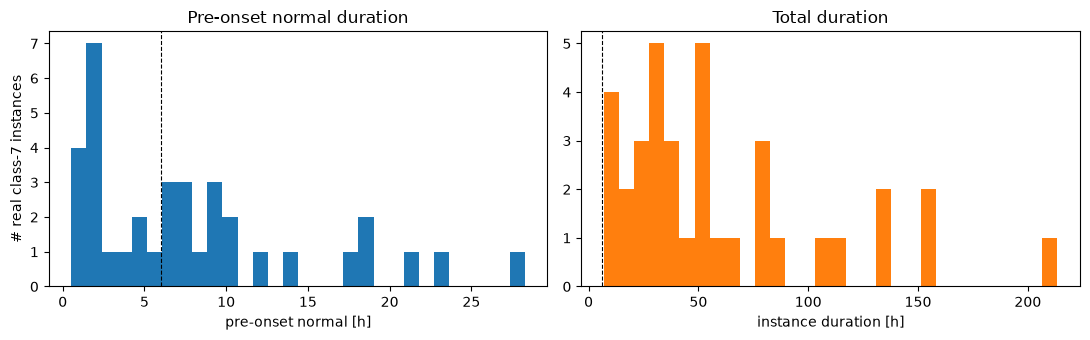

In [7]:
FIGS.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(c7_real.pre_normal_h, bins=30); ax[0].set(xlabel="pre-onset normal [h]", ylabel="# real class-7 instances", title="Pre-onset normal duration")
ax[1].hist(c7_real.duration_h, bins=30, color="C1"); ax[1].set(xlabel="instance duration [h]", title="Total duration")
for a in ax: a.axvline(6, ls="--", c="k", lw=.8)  # 6 h = longest rolling window (360 min)
fig.tight_layout(); fig.savefig(FIGS / "eda_class7_durations.png", dpi=150)

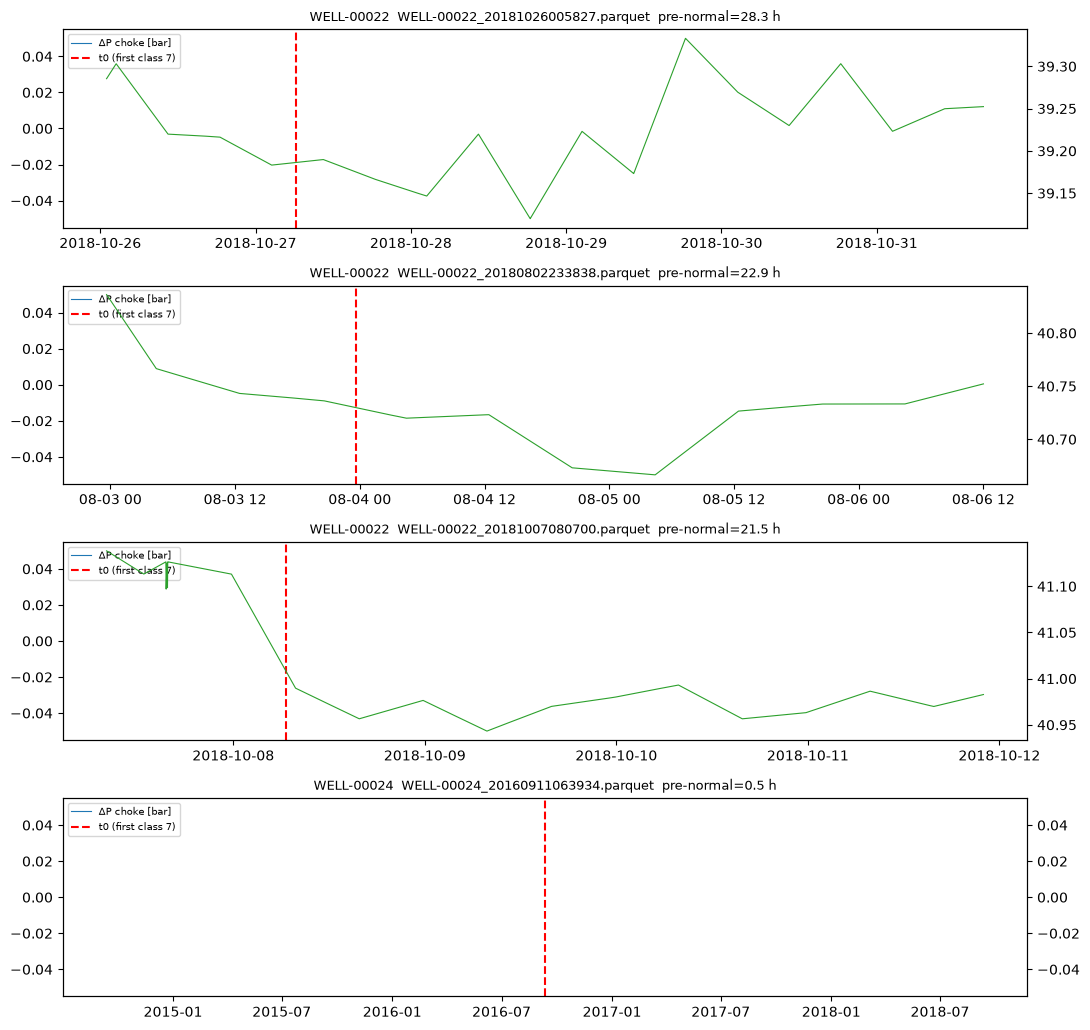

In [8]:
# Three real instances with the longest pre-onset normal + one with the shortest, to see what onset looks like.
show = pd.concat([c7_real.nlargest(3, "pre_normal_h"), c7_real.nsmallest(1, "pre_normal_h")])
fig, axes = plt.subplots(len(show), 1, figsize=(11, 2.6 * len(show)))
for ax, (_, r) in zip(axes, show.iterrows()):
    d = pd.read_parquet(r.path, columns=["P-MON-CKP", "P-JUS-CKP", "ABER-CKP", "class"]).resample("1min").mean()
    ax.plot(d.index, (d["P-MON-CKP"] - d["P-JUS-CKP"]) / 1e5, lw=.8, label="ΔP choke [bar]")
    ax2 = ax.twinx(); ax2.plot(d.index, d["ABER-CKP"], c="C2", lw=.8, label="ABER-CKP [%]")
    if pd.notna(r.t0): ax.axvline(r.t0, c="r", ls="--", label="t0 (first class 7)")
    ax.set_title(f"{r.well}  {r.path.name}  pre-normal={r.pre_normal_h:.1f} h", fontsize=9); ax.legend(loc="upper left", fontsize=7)
fig.tight_layout(); fig.savefig(FIGS / "eda_class7_examples.png", dpi=150)

## 5. Missingness of key channels in class-7 real instances
RI needs P-MON-CKP, P-JUS-CKP, ABER-CKP; ΔT needs T-MON-CKP, T-JUS-CKP. If these are missing
in scaling wells, the physics branch (and the RI fallback) is in trouble.

In [9]:
key = ["P-MON-CKP", "P-JUS-CKP", "ABER-CKP", "T-MON-CKP", "T-JUS-CKP", "P-PDG", "P-TPT", "T-TPT", "QGL"]
miss = pd.DataFrame({r.path.name: pd.read_parquet(r.path, columns=key).isna().mean() for _, r in c7_real.iterrows()}).T
print("fraction of class-7 real instances where channel is >50 % missing:")
(miss > 0.5).mean().round(2)

fraction of class-7 real instances where channel is >50 % missing:


P-MON-CKP    0.00
P-JUS-CKP    1.00
ABER-CKP     0.78
T-MON-CKP    1.00
T-JUS-CKP    0.11
P-PDG        0.17
P-TPT        0.11
T-TPT        0.03
QGL          0.33
dtype: float64

## 6. Verdict
Criterion fixed **before** looking at results (so it is not tuned to a desired answer):
an instance is *usable* for survival if it has ≥ 6 h labelled-normal data before t0
(6 h = the longest rolling window, so at least one complete feature window ends before onset, and
several horizon bins up to a few hours can be populated). Survival target is **feasible** if
≥ 50 % of real class-7 instances AND ≥ 5 distinct wells are usable (5 wells = minimum for a
meaningful leave-one-well-out with a separate calibration well).

In [10]:
THR_H = 6
usable = c7_real[c7_real.pre_normal_h >= THR_H]
frac, n_wells = len(usable) / len(c7_real), usable.well.nunique()
for h in [0, 1, 6, 24, 72]:
    u = c7_real[c7_real.pre_normal_h > h] if h == 0 else c7_real[c7_real.pre_normal_h >= h]
    print(f"pre-onset normal {'>' if h==0 else '>='} {h:>3} h: {len(u):>2}/{len(c7_real)} instances, {u.well.nunique()} wells")
feasible = frac >= 0.5 and n_wells >= 5
print("\nVERDICT:", "survival target FEASIBLE" if feasible else "use RI-crossing FALLBACK",
      f"(usable {len(usable)}/{len(c7_real)} = {frac:.0%}, {n_wells} wells)")

pre-onset normal >   0 h: 36/36 instances, 6 wells
pre-onset normal >=   1 h: 35/36 instances, 6 wells
pre-onset normal >=   6 h: 20/36 instances, 5 wells
pre-onset normal >=  24 h:  1/36 instances, 1 wells
pre-onset normal >=  72 h:  0/36 instances, 0 wells

VERDICT: survival target FEASIBLE (usable 20/36 = 56%, 5 wells)


## 7. Which channels move after onset? (RI substitute)
Planned RI needs P-JUS-CKP (100 % missing in class-7 real instances) and ABER-CKP (78 % missing),
so we test which *available* channels shift after t0. z = (mean of last 2 h − pre-onset mean) / pre-onset std.
Physics expectation: scale narrows the choke throat → upstream pressure P-MON-CKP rises; larger
pressure drop → stronger Joule–Thomson cooling → downstream temperature T-JUS-CKP falls.

In [11]:
vars_ = ["P-MON-CKP","P-TPT","P-ANULAR","P-JUS-CKGL","T-JUS-CKP","T-TPT","QGL","ABER-CKP","P-JUS-CKP","T-MON-CKP","P-PDG"]
rows = []
for _, r in c7_real.iterrows():
    d = pd.read_parquet(r.path, columns=vars_).resample("10min").mean()
    pre, post = d[d.index < r.t0], d[d.index >= r.t0]
    for v in vars_:
        a, b = pre[v].dropna(), post[v].dropna()
        ok = len(a) >= 6 and len(b) >= 12 and a.std() > 0   # WHY: need enough points on both sides
        rows.append(dict(well=r.well, var=v, avail=ok,
                         z=(b.iloc[-12:].mean() - a.mean()) / a.std() if ok else np.nan,
                         rel=(b.iloc[-12:].mean() - a.mean()) / abs(a.mean()) if ok else np.nan))
shift = pd.DataFrame(rows)
shift.groupby("var").agg(avail=("avail","mean"), z_median=("z","median"), rel_median=("rel","median"),
                         frac_up=("z", lambda s: (s > 2).mean()), frac_down=("z", lambda s: (s < -2).mean())
                        ).sort_values("avail", ascending=False).round(3)

,avail,z_median,rel_median,frac_up,frac_down
var,,,,,
P-JUS-CKGL,1.000,3.737,0.018,0.583,0.139
P-MON-CKP,1.000,7.909,0.066,0.889,0.000
T-JUS-CKP,0.889,-4.804,-0.026,0.028,0.556
T-TPT,0.889,1.922,0.001,0.444,0.194
P-ANULAR,0.861,9.303,0.007,0.639,0.028
P-TPT,0.861,13.515,0.009,0.722,0.000
QGL,0.528,-1.100,-0.005,0.056,0.194
ABER-CKP,0.222,0.040,-0.000,0.028,0.028
P-PDG,0.028,1.964,0.000,0.000,0.000


## 8. Proxy RI* = P-MON-CKP / pre-onset median — how long until it crosses 2 / 5 / 10 %?
Self-referenced (each instance's own pre-onset median) because 4 of 6 scaling wells have no normal files.
Time from t0 to crossing tells us the forecast horizon scale the data can support.

In [12]:
res = []
for _, r in c7_real.iterrows():
    p = pd.read_parquet(r.path, columns=["P-MON-CKP"])["P-MON-CKP"].resample("10min").mean()
    ri = (p / p[p.index < r.t0].median()).rolling(6, min_periods=3).median()  # 1 h median: robust to spikes
    post = ri[ri.index >= r.t0]
    d = dict(well=r.well, post_h=r.post_h, ri_end=post.iloc[-6:].mean())
    for th in (1.02, 1.05, 1.10):
        hit = post[post >= th]
        d[f"h_to_{th}"] = (hit.index[0] - r.t0).total_seconds() / 3600 if len(hit) else np.nan
    res.append(d)
cross = pd.DataFrame(res); cross.to_csv(TABLES / "class7_ri_star_crossing.csv", index=False)
display(cross.groupby("well")[["ri_end","h_to_1.02","h_to_1.05","h_to_1.1"]].median().round(2))
for c in ["h_to_1.02","h_to_1.05","h_to_1.1"]:
    s = cross[c]; print(f"{c}: crossed {s.notna().sum()}/{len(s)}, median {s.median():.1f} h, >24 h: {(s > 24).sum()}")

,ri_end,h_to_1.02,h_to_1.05,h_to_1.1
well,,,,
WELL-00001,1.06,4.76,8.60,NaN
WELL-00006,1.07,10.69,19.35,NaN
WELL-00021,1.05,2.64,3.02,NaN
WELL-00022,1.03,39.17,118.11,NaN
WELL-00023,1.03,70.55,NaN,NaN
WELL-00024,1.21,1.31,5.29,12.31


h_to_1.02: crossed 35/36, median 4.3 h, >24 h: 11
h_to_1.05: crossed 25/36, median 6.9 h, >24 h: 3
h_to_1.1: crossed 15/36, median 12.3 h, >24 h: 2
